# Surface potential density (rhopot0) and difference from WOA23

Based on `SST.ipynb`. Model surface density is the top level of `rhopot0`; the WOA23 surface density is computed with TEOS-10 (`gsw`) from WOA23 conservative temperature and absolute salinity.

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest

# Second experiment to compare against (set to None to skip the comparison)
esm_file_compare = None
esm_file = "/g/data/x77/kc5856/outputs/access-om3/OM3_MC_25km_jra_iaf_cycle2_control-expt-74114deb/experiment_datastore.json"
# esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# What physical field you want, in CF terms (stays the same across models)
# rhopot0 has no CF standard_name in the catalog, so we select it by variable name
variable_standard_name = None

# Fallback variable name to use if the catalog doesn’t expose standard_name
fallback_variable_names = ["rhopot0"]

# Reference / observational dataset (we'll use this later when we get to the WOA block)
obs_file_pattern = "/g/data/ik11/inputs/access-om3/woa23/025/2025.08.26/woa23_ts_*"  # matches 25km/0.25deg grid
# obs_file_pattern = "/g/data/ik11/inputs/access-om3/woa23/1deg/2026.02.17/woa23_ts_*"  # matches the 100km/1deg grid
obs_var_name = "temp"   # conservative temperature [degC]
obs_salt_name = "salt"  # absolute salinity [g/kg]

# Frequency depends on the datastore you’re using:
data_frequency = "1mon"

# Averaging window: last NYEARS complete years, or an explicit [first, last] period
averaging_period = None   # e.g. [1905, 1909]; None = automatic
NYEARS = 1

# This notebook lives outside the repo, so point at the repo's notebooks/ folder for the helper modules
notebooks_dir = "/home/272/kc5856/git_contributions/access-om3-paper-1/notebooks"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import sys
sys.path.insert(0, notebooks_dir)  # find mkfigs_bootstrap, exptdata_access, model_agnostic
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from exptdata_access import get_experiment_info, guess_experiment_from_esm_file
from model_agnostic import get_lon_lat_from_catalog, select_variable, patch_broken_conda_env
patch_broken_conda_env()  # conda env workaround for analysis3-26.03+; no-op on healthy envs
# Infer model information from the datastore path
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]             # OM3 or CM3

In [3]:
import xarray as xr
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import intake
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from distributed import Client
import cftime
import os
import cmocean as cm
import gsw
import cartopy.feature as cft
from textwrap import wrap
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default

In [4]:
from model_agnostic import patch_dask_workers
client = Client(threads_per_worker=1)
patch_dask_workers(client)  # patch workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/8787/status,
Dashboard: /proxy/8787/status,Workers: 28
Total threads: 28,Total memory: 125.19 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:39019,Workers: 0
Dashboard: /proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38725,Total threads: 1
Dashboard: /proxy/38707/status,Memory: 4.47 GiB
Nanny: tcp://127.0.0.1:39953,


### Define plot function

In [5]:
blue_marble = plt.imread('/g/data/ik11/grids/BlueMarble.tiff')
blue_marble_extent = (-180, 180, -90, 90)

In [6]:
def plot(dat, title=None, projection=None, add_blue_marble=True, **kwargs):
    """
    Generic 2D map plot helper for model / obs / bias fields.

    - Works for any variable (SST, SSH, salinity, etc.).
    - Assumes the last two dimensions are (y, x) horizontal dims.
    - Uses contourf with a cartopy projection.
    """

    import matplotlib.pyplot as plt
    import cartopy.crs as ccrs
    from textwrap import wrap

    # Make sure we're working with a DataArray
    da = dat
    if not isinstance(da, xr.DataArray):
        raise TypeError("plot() expects an xarray.DataArray")

    # Handle simple time dimension cases (e.g. time-mean or single time step)
    if da.ndim == 3 and "time" in da.dims and da.sizes["time"] == 1:
        da = da.isel(time=0, drop=True)

    if da.ndim != 2:
        raise ValueError(
            f"plot() expects a 2D field or a 3D field with singleton time; got dims {da.dims}"
        )

    # Infer horizontal dims as the last two dims
    ydim, xdim = da.dims[-2], da.dims[-1]

    # Title and colourbar label from attributes
    long_name = da.attrs.get("long_name", da.name or "Field")
    units = da.attrs.get("units", "")

    if title is None:
        title = long_name

    cbar_label = long_name if units == "" else f"{long_name} [{units}]"
    cbar_label = "\n".join(wrap(cbar_label, 45))

    # Projection: default to Robinson
    if projection is None:
        projection = ccrs.Robinson(central_longitude=-100)

    fig = plt.figure(figsize=(12, 6))
    ax = plt.axes(projection=projection)

    # Main filled contour plot
    da.plot.contourf(
        ax=ax,
        x=xdim,
        y=ydim,
        transform=ccrs.PlateCarree(),
        cbar_kwargs={
            "label": cbar_label,
            "fraction": 0.03,
            "aspect": 15,
            "shrink": 0.7,
        },
        **kwargs,
    )

    # Optional blue marble overlay if available
    if add_blue_marble and "blue_marble" in globals() and "blue_marble_extent" in globals():
        ax.imshow(
            blue_marble,
            extent=blue_marble_extent,
            transform=ccrs.PlateCarree(),
            origin="upper",
        )

    ax.coastlines()
    plt.title(title)
    plt.tight_layout()

### Load and plot data from ESM datastore

In [7]:
from exptdata_access import get_exptname_from_path
exptname=get_exptname_from_path(esm_file)
print("Experiment name:", exptname)

datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units"
    ]
)

Experiment name: OM3_MC_25km_jra_iaf_cycle2_control-expt-74114deb


In [8]:
da_model = select_variable(
    datastore,
    variable_standard_name,
    fallback_variable_names,
    data_frequency=data_frequency,
)
print("Selected variable:", da_model.name)
print("dims:", da_model.dims)

Selected variable via fallback name: rhopot0
Selected variable: rhopot0
dims: ('time', 'z_l', 'yh', 'xh')


In [9]:
# Load model grid and attach true lon/lat to the model field
# (uses the catalog-driven helper, robust to both ACCESS-OM3's output000/*.mom6.static.nc
# layout and ACCESS-CM3's differently-named/located static files -- a hardcoded
# "output000/access-om3.mom6.static.nc" path only exists for ACCESS-OM3)
geolon, geolat = get_lon_lat_from_catalog(datastore)

model_all = da_model.cf.assign_coords(
    {
        "longitude": geolon,
        "latitude": geolat,
    }
)
print("Attached geolon/geolat from catalog grid variables.")
print("model_all dims:", model_all.dims)

Attached geolon/geolat from catalog grid variables.
model_all dims: ('time', 'z_l', 'yh', 'xh')


In [10]:
from model_agnostic import years_window, year_slice

# Window chosen on the native time axis (before any calendar conversion, so
# daily noleap data are not made to look incomplete in leap years)
om3_window = years_window(model_all.time, NYEARS, period=averaging_period)
period_label = f"{om3_window[0]}-{om3_window[1]} mean"
print("Full model time range:", model_all.time.values[0], "->", model_all.time.values[-1])
print("Averaging window:", om3_window)


Full model time range: 1958-01-02 00:00:00 -> 2003-12-16 12:00:00
Averaging window: (2003, 2003)


In [11]:
model_window = model_all.sel(time=year_slice(om3_window))
print("Windowed dims:", model_window.dims, "ntime =", model_window.sizes["time"])


Windowed dims: ('time', 'z_l', 'yh', 'xh') ntime = 12


In [12]:
%%time
model = (
    model_window
    .isel(z_l=0)              # surface level
    .cf.mean("time")          # CF-aware: whatever the time dim is called
    .pint.quantify()          # attach Pint units from attrs["units"]
    .pint.to("kg/m^3")        # make sure units are kg m-3
    .pint.dequantify()        # back to plain DataArray for plotting / saving
)

print("Final model dims:", model.dims)
print("Final model units:", model.attrs.get("units"))

Final model dims: ('yh', 'xh')
Final model units: kilogram / meter ** 3
CPU times: user 241 ms, sys: 108 ms, total: 349 ms
Wall time: 273 ms


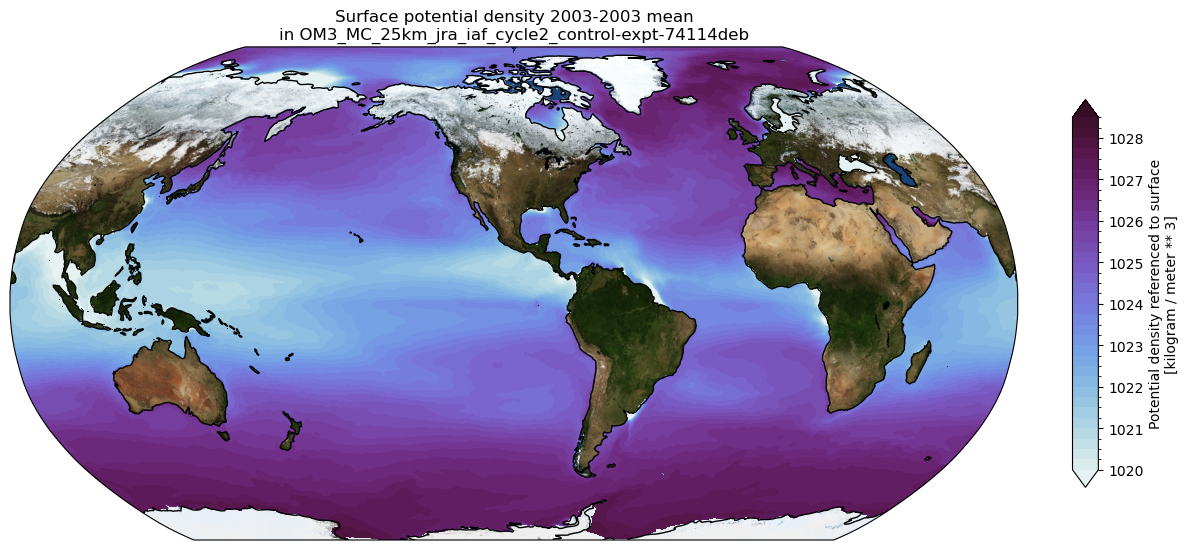

In [13]:
long_name = "Surface potential density"

plot(
    model,
    levels=35,
    vmin=1020,
    vmax=1028.5,
    extend="both",
    cmap=cm.cm.dense,
    title=(
        f"{long_name} "
        f"{period_label}\nin {exptname}"
    ),
)
mkmd.savefig(plt.gcf(), "Surface Potential Density", "ACCESS-OM3 surface potential density (rhopot0, top level).")

### Load and plot data from MC comparison experiment

In [14]:
if esm_file_compare is not None:
    exptname_compare = get_exptname_from_path(esm_file_compare)
    print("Comparison experiment name:", exptname_compare)

    datastore_compare = intake.open_esm_datastore(
        esm_file_compare,
        columns_with_iterables=[
            "variable",
            "variable_long_name",
            "variable_standard_name",
            "variable_cell_methods",
            "variable_units"
        ]
    )

    da_model_compare = select_variable(
        datastore_compare,
        variable_standard_name,
        fallback_variable_names,
        data_frequency=data_frequency,
    )
    print("Selected variable:", da_model_compare.name)
    print("dims:", da_model_compare.dims)

In [15]:
if esm_file_compare is not None:
    geolon_compare, geolat_compare = get_lon_lat_from_catalog(datastore_compare)

    model_all_compare = da_model_compare.cf.assign_coords(
        {
            "longitude": geolon_compare,
            "latitude": geolat_compare,
        }
    )
    print("model_all_compare dims:", model_all_compare.dims)

In [16]:
if esm_file_compare is not None:
    # Match the selected model window, including explicit multi-year periods.
    # Partial overlap warns; no overlap falls back to the same number of
    # complete years at the start of the reference run, with a warning.
    ref_nyears = om3_window[1] - om3_window[0] + 1
    ref_window = years_window(model_all_compare.time, ref_nyears, within=om3_window, fallback="last")
    period_label_compare = f"{ref_window[0]}-{ref_window[1]} mean"
    model_window_compare = model_all_compare.sel(time=year_slice(ref_window))
    print("Comparison averaging window:", ref_window)


In [17]:
if esm_file_compare is not None:
    model_compare = (
        model_window_compare
        .isel(z_l=0)
        .cf.mean("time")
        .pint.quantify()
        .pint.to("kg/m^3")
        .pint.dequantify()
    )
    print("Final model_compare units:", model_compare.attrs.get("units"))

In [18]:
if esm_file_compare is not None:
    long_name_compare = "Surface potential density"

    plot(
        model_compare,
        levels=35,
        vmin=1020,
        vmax=1028.5,
        extend="both",
        cmap=cm.cm.dense,
        title=(
            f"{long_name_compare} "
            f"{period_label_compare}\nin {exptname_compare}"
        ),
    )
    mkmd.savefig(plt.gcf(), "Surface Potential Density (comparison)", f"{exptname_compare} surface potential density (rhopot0, top level).")

### Load data from WOA23 and compute surface potential density
WOA23 files hold TEOS-10 conservative temperature and absolute salinity. The model uses `EQN_OF_STATE = ROQUET_RHO` (a polynomial fit to TEOS-10), so `gsw.rho(SA, CT, p=0)` is the consistent observed equivalent. Density is computed for each monthly climatology, then averaged.

In [19]:
# Load observational / reference data (e.g. WOA23) in a model-agnostic way.
# WOA23 products by model grid shape: the obs is assigned directly onto the model
# grid below, so the two must have identical shape. Pick the product that matches
# rather than hard-coding one resolution (lets this notebook run at 25km and 100km).
woa_products = {
    (1152, 1440): "/g/data/ik11/inputs/access-om3/woa23/025/2025.08.26/woa23_ts_*",   # 25km / 0.25deg grid
    (324, 360):   "/g/data/ik11/inputs/access-om3/woa23/1deg/2026.02.17/woa23_ts_*",  # 100km / 1deg grid
    (300, 360):   "/g/data/ik11/inputs/access-om3/woa23/1deg/2025.10.24/woa23_ts_*",  # 100km / 1deg grid (300 rows)
    (3672, 4320): "/g/data/ik11/inputs/access-om3/woa23/8km/2026.09.17/woa23_ts_*",   # 8km grid
    (3360, 4320): "/g/data/vk83/prerelease/configurations/inputs/access-om3/mom/initial_conditions/global.8km/2026.10.07/woa23_ts_*_mom.nc",  # 8km grid (hgrid 2026.10.07)
}

def load_woa_on_grid(lon2d, lat2d, default_pattern=None):
    """Load the WOA23 product matching this model grid, compute surface potential
    density (TEOS-10, referenced to 0 dbar), and place it on that grid.

    Returns (obs_on_native_dims, obs_with_model_lon_lat_coords).
    """
    default_pattern = obs_file_pattern if default_pattern is None else default_pattern
    shape = tuple(lat2d.shape[-2:])
    pattern = woa_products.get(shape, default_pattern)
    print(f"model grid {shape} -> obs {pattern}")
    ds_obs = xr.open_mfdataset(pattern, chunks={"time": -1})
    try:
        ds_obs_sfc = ds_obs.cf.isel(Z=0)          # first depth level
    except Exception:
        ds_obs_sfc = ds_obs.isel(depth=0)         # fallback if depth is literally 'depth'
    CT = ds_obs_sfc[obs_var_name]
    SA = ds_obs_sfc[obs_salt_name]
    rho = xr.apply_ufunc(gsw.rho, SA, CT, 0, dask="parallelized", output_dtypes=[float])
    o = rho.cf.mean("time")                       # annual mean of the monthly densities
    o.attrs = {"long_name": "Surface potential density (WOA23, TEOS-10)", "units": "kg m-3"}
    if {"yh", "xh"}.issubset(o.dims):
        grid = o
    elif {"lat", "lon"}.issubset(o.dims):
        grid = o.rename({"lat": "yh", "lon": "xh"})
    else:
        raise ValueError("Obs grid dims not recognized; expected yh/xh or lat/lon")
    return grid, grid.cf.assign_coords({"longitude": lon2d, "latitude": lat2d})

obs_grid, obs = load_woa_on_grid(geolon, geolat)

print("Obs dims:", obs.dims)
print("Obs coords:", list(obs.coords))

model grid (1152, 1440) -> obs /g/data/ik11/inputs/access-om3/woa23/025/2025.08.26/woa23_ts_*
Obs dims: ('yh', 'xh')
Obs coords: ['depth', 'xh', 'yh']


### Plot model minus WOA23
First plot full range, then a fixed range.

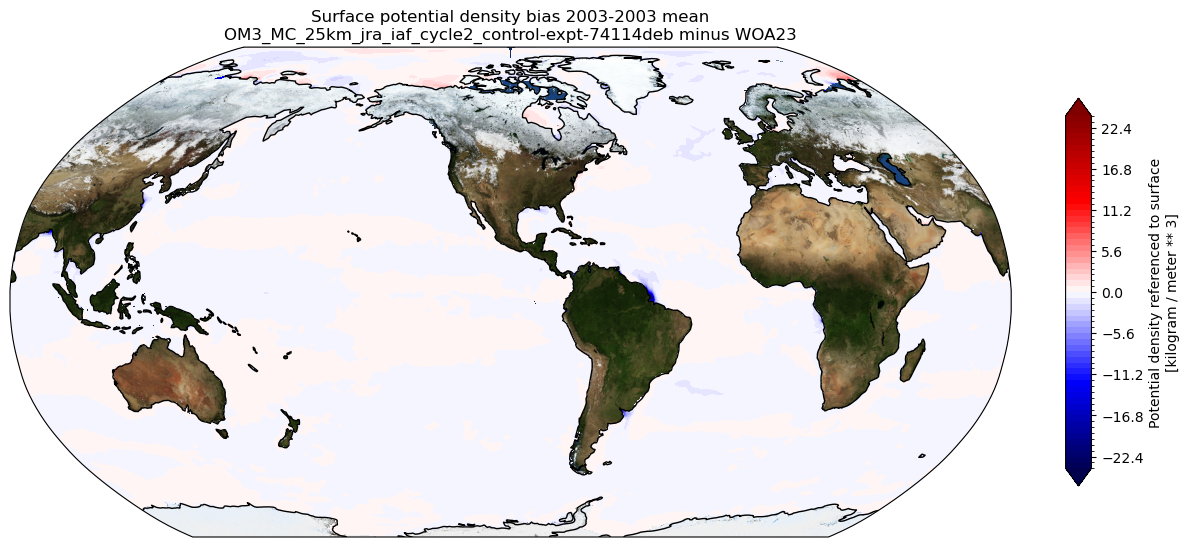

In [20]:
# 1) Obs is already on the model grid with geolon/geolat coordinates
obs_on_model = obs

# 2) Compute bias directly (units already consistent)
bias = (model - obs_on_model).load()
bias.attrs = model.attrs

# 3) Plot the bias
long_name = "Surface potential density"

plot(
    bias,
    levels=61,
    extend="both",
    cmap="seismic",
    title=(
        f"{long_name} bias "
        f"{period_label}\n{exptname} minus WOA23"
    ),
)

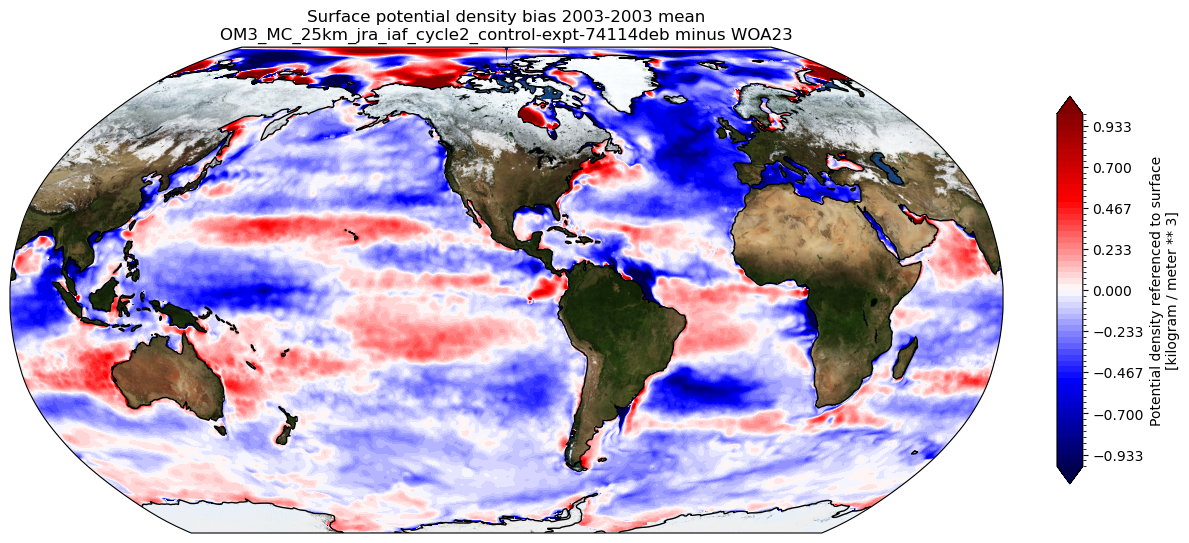

In [21]:
plot(
    bias,
    levels=61,
    vmin=-1,
    vmax=1,
    extend="both",
    cmap="seismic",
    title=(
        f"{long_name} bias "
        f"{period_label}\n{exptname} minus WOA23"
    ),
)
mkmd.savefig(plt.gcf(), "Surface Potential Density Bias", "ACCESS-OM3 surface potential density minus WOA23 (TEOS-10).")

In [22]:
if esm_file_compare is not None:
    # Obs on the comparison model's own grid. If it is a different resolution to
    # the main model, re-load the matching WOA product rather than reusing obs_grid.
    if tuple(geolat_compare.shape[-2:]) == tuple(geolat.shape[-2:]):
        obs_compare_grid = obs_grid.cf.assign_coords(
            {
                "longitude": geolon_compare,
                "latitude": geolat_compare,
            }
        )
    else:
        _, obs_compare_grid = load_woa_on_grid(geolon_compare, geolat_compare)

In [23]:
if esm_file_compare is not None:
    bias_compare = (model_compare - obs_compare_grid).load()
    bias_compare.attrs = model_compare.attrs

    plot(
        bias_compare,
        levels=61,
        vmin=-1,
        vmax=1,
        extend="both",
        cmap="seismic",
        title=(
            f"{long_name_compare} bias "
            f"{period_label_compare}\n{exptname_compare} minus WOA23"
        ),
    )
    mkmd.savefig(plt.gcf(), "Surface Potential Density Bias (comparison)", f"{exptname_compare} surface potential density minus WOA23 (TEOS-10).")

In [ ]:
client.close()